# Processing and analyzing scATAC-seq data

1. [Proprocessing](#section1)
    * Create arrowfiles with merged lung samples and spleen samples
    * Infer doublets
    * Create an ArchRProject
    * Data QC
2. [Dimensionality reduction and clustering](#section2)
    * batch effect not corrected
3. [Annotating cell clusters](#section3)
    * Annotate cells with cell type labels from expression data
4. [Peak calling in each cell type](#section4)
5. [Identifying marker peaks for each cel type](#section5)
6. [Cross-tissue differential accessibility analysis by pseudobulk](#section6)

In [1]:
## Load packages and set up environment
library(ArchR)
library(dplyr)
library(tidyr)
library(BSgenome.Hsapiens.UCSC.hg38)
#library(plotly)
set.seed(1)
addArchRThreads(threads = 12) 
addArchRGenome("hg38")


                                                   / |
                                                 /    \
            .                                  /      |.
            \\\                              /        |.
              \\\                          /           `|.
                \\\                      /              |.
                  \                    /                |\
                  \\#####\           /                  ||
                ==###########>      /                   ||
                 \\##==......\    /                     ||
            ______ =       =|__ /__                     ||      \\\
        ,--' ,----`-,__ ___/'  --,-`-===================##========>
       \               '        ##_______ _____ ,--,__,=##,__   ///
        ,    __==    ___,-,__,--'#'  ==='      `-'    | ##,-/
        -,____,---'       \\####\\________________,--\\_##,/
           ___      .______        ______  __    __  .______      
          /   \     |   _ 

### A table of sample QC summary statistics


In [3]:
summary <- fread("cellranger_outs/cellranger_QC_summary.csv")

selected_cols <-
summary %>%
filter(!`Sample ID` %in% c('CO-NS-10X-11s-COB-2',
                          'CO-NS-10X-11s-COB-3',
                          'CO-NS-10X-11s-COB-4')) %>%
select(`Sample ID`, 
       `Estimated number of cells`,
        `ATAC Median high-quality fragments per cell`,
        `GEX Median genes per cell`,
        `GEX Median UMI counts per cell`,
        `GEX Fraction of transcriptomic reads in cells`,
        `ATAC TSS enrichment score`,
        `ATAC Confidently mapped read pairs`
       )
selected_cols

Sample ID,Estimated number of cells,ATAC Median high-quality fragments per cell,GEX Median genes per cell,GEX Median UMI counts per cell,GEX Fraction of transcriptomic reads in cells,ATAC TSS enrichment score,ATAC Confidently mapped read pairs
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
CO-NS-10X-11s-COB-10,4567,8732.0,46,81,0.8241,8.5785,0.8976
CO-NS-10X-11s-COB-11,5646,7856.0,59,90,0.8451,8.5779,0.8998
CO-NS-10X-11s-COB-5,20000,1192.0,34,39,0.4204,9.0837,0.8873
CO-NS-10X-11s-COB-6,10999,5348.0,179,285,0.8399,8.9773,0.8899
CO-NS-10X-11s-COB-7,12194,4837.0,67,133,0.8227,8.2463,0.9051
CO-NS-10X-11s-COB-8,7857,2106.0,9,11,0.7077,5.0626,0.8922
CO-NS-10X-11s-COB-9,9157,4182.0,20,31,0.7971,7.9251,0.8992
CO-NS-10X-6S-Multi-6S-SMO-10,8398,8787.0,1329,2563,0.8764,8.7134,0.8902
CO-NS-10X-6S-Multi-6S-SMO-4,3133,14117.0,973,1737,0.8734,10.4837,0.8838


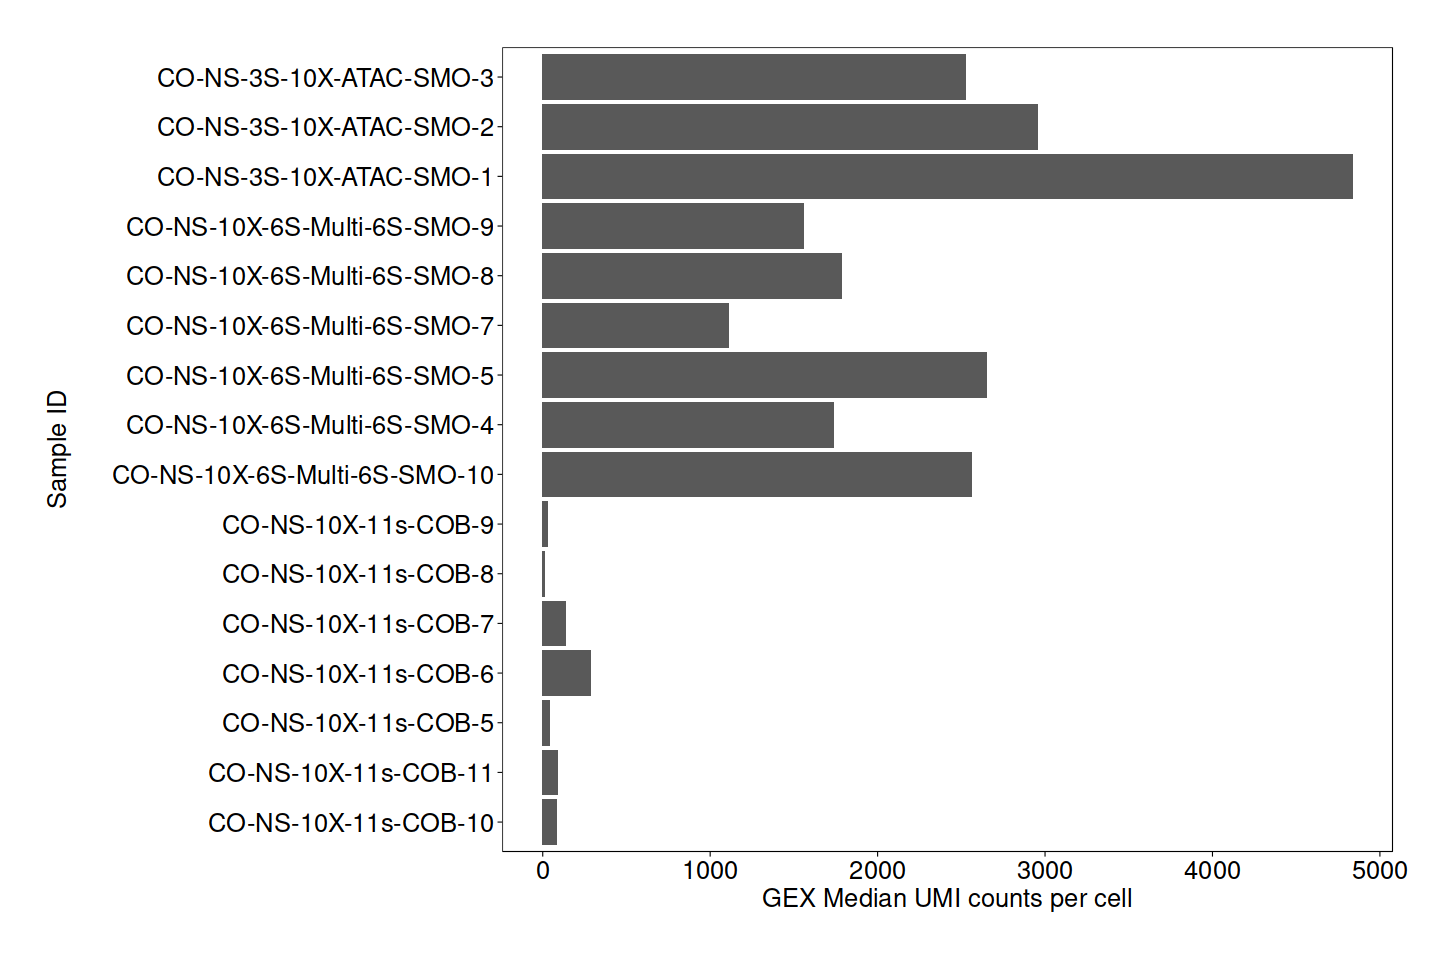

In [29]:
ggplot(selected_cols,
       aes(x = `Sample ID`,
           y = `GEX Median UMI counts per cell`)) + 
geom_col() + coord_flip() + theme_ArchR(baseSize = 15)

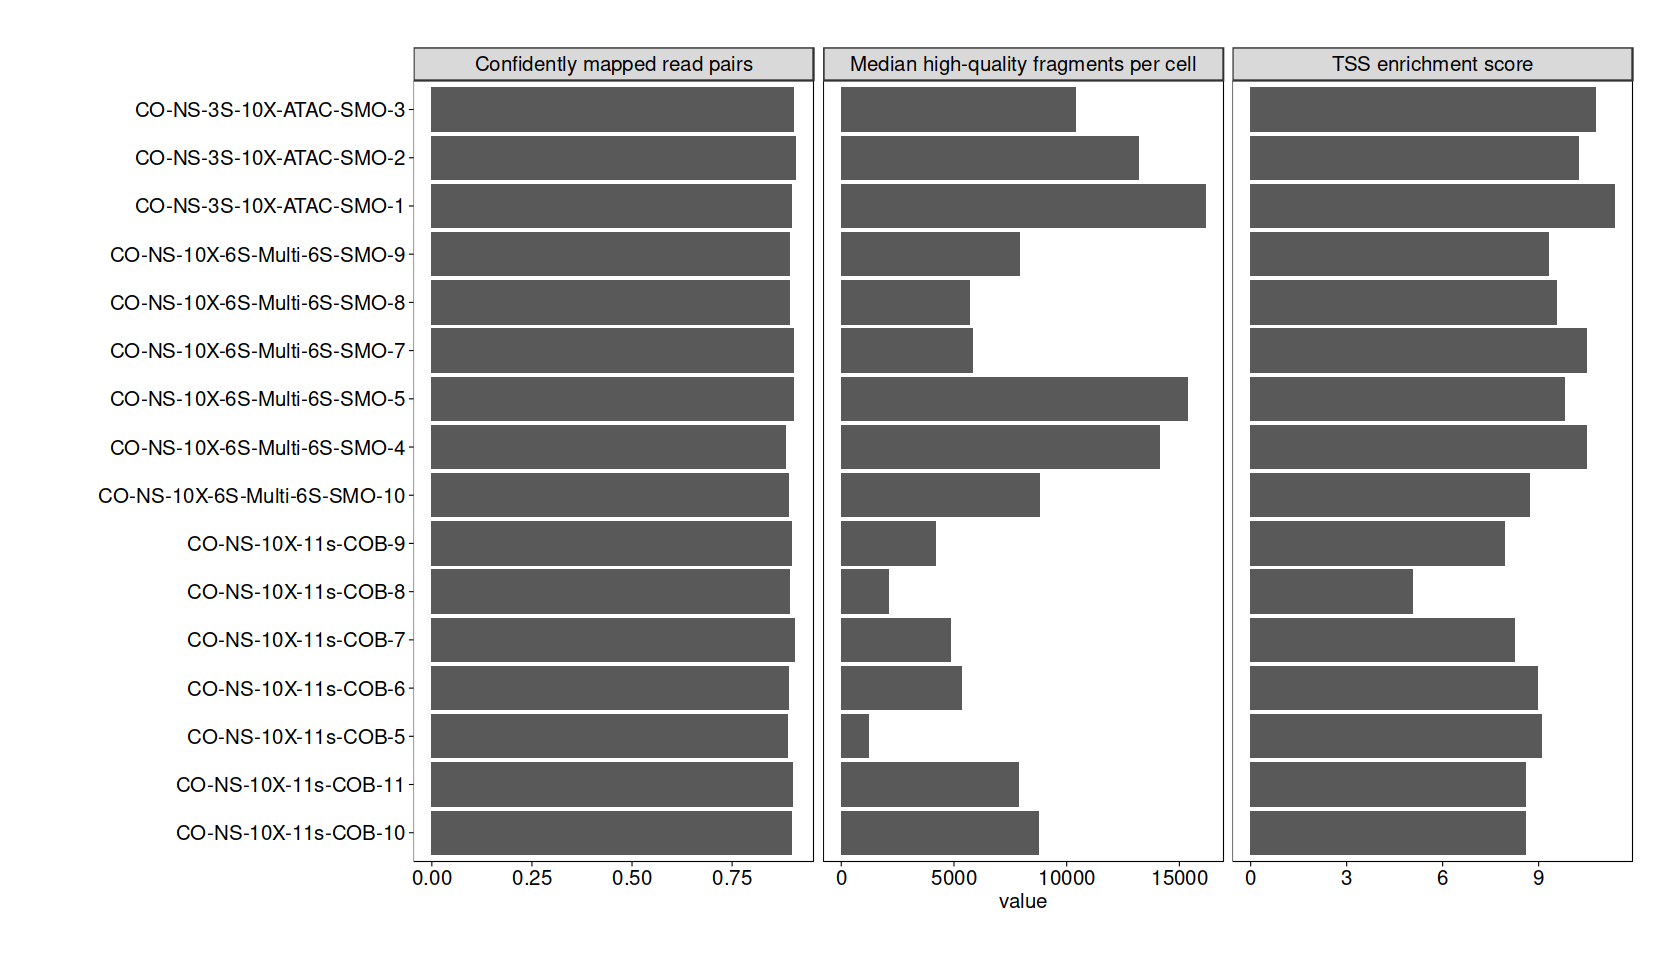

In [69]:
options(repr.plot.width=14, repr.plot.height=8)
selected_cols %>% 
pivot_longer(cols=!c(1,2,4,5,6),
             names_to="name", 
             values_to="value") %>%
mutate(name=gsub("ATAC ", "", name)) %>%
ggplot(aes(y = value, x = `Sample ID`)) + 
geom_col() + coord_flip() + xlab("") + 
facet_wrap(~ name, scale="free_x") + 
theme_ArchR(baseSize = 12)

<a id='section1'></a>
## 1 Preprocessing chromatin accessibility data

In [1]:
sample_list <- c(
       "CO-NS-10X-11s-COB-10
        CO-NS-10X-11s-COB-11
        CO-NS-10X-11s-COB-6
        CO-NS-10X-11s-COB-7
        CO-NS-10X-11s-COB-8
        CO-NS-10X-11s-COB-9
        CO-NS-10X-6S-Multi-6S-SMO-10
        CO-NS-10X-6S-Multi-6S-SMO-4
        CO-NS-10X-6S-Multi-6S-SMO-5
        CO-NS-10X-6S-Multi-6S-SMO-7
        CO-NS-10X-6S-Multi-6S-SMO-8
        CO-NS-10X-6S-Multi-6S-SMO-9
        CO-NS-3S-10X-ATAC-SMO-1
        CO-NS-3S-10X-ATAC-SMO-2
        CO-NS-3S-10X-ATAC-SMO-3")
sample_list <- unlist(lapply(strsplit(sample_list, "\n"), trimws))

In [ ]:
## Build ArchR objects

sampleID<-unlist(lapply(sample_list$V1, function(i){paste(rev(strsplit(i, "-")[[1]])[2:1], 
                                                   collapse="-")}))
ArrowFiles <- createArrowFiles(
  inputFiles = sprintf("~/projects/u19_multiomics/data/cellranger_outs/%s/outs/atac_fragments.tsv.gz", 
                       sample_list$V1),
  sampleNames = sampleID,
  minTSS = 4, 
  minFrags = 1000, 
  addTileMat = TRUE,
  addGeneScoreMat = TRUE,
  force=TRUE
)
proj <- ArchRProject(
  ArrowFiles = ArrowFiles, 
  outputDirectory = "/home/jinggu/jinggu/project/u19_project/u19_all_samples",
  copyArrows = TRUE #This is recommened so that you maintain an unaltered copy for later usage.
)
doubScores <- addDoubletScores(
    # detect doublets
  input = ArrowFiles,
  k = 10, #Refers to how many cells near a "pseudo-doublet" to count.
  knnMethod = "UMAP", #Refers to the embedding to use for nearest neighbor search.
  LSIMethod = 1
)

proj <- ArchRProject(
  ArrowFiles = ArrowFiles, 
  outputDirectory = "u19_all_samples",
  copyArrows = TRUE #This is recommened so that you maintain an unaltered copy for later usage.
)

proj <- filterDoublets(ArchRProj = proj)

In [ ]:
p1 <- plotGroups(
    ArchRProj = proj, 
    groupBy = "Sample", 
    colorBy = "cellColData", 
    name = "TSSEnrichment",
    plotAs = "ridges"
   )
p2 <- plotGroups(
    ArchRProj = proj, 
    groupBy = "Sample", 
    colorBy = "cellColData", 
    name = "TSSEnrichment",
    plotAs = "violin",
    alpha = 0.4,
    addBoxPlot = TRUE
   )
p3 <- plotGroups(
    ArchRProj = proj, 
    groupBy = "Sample", 
    colorBy = "cellColData", 
    name = "log10(nFrags)",
    plotAs = "ridges"
   )
p4 <- plotGroups(
    ArchRProj = proj, 
    groupBy = "Sample", 
    colorBy = "cellColData", 
    name = "log10(nFrags)",
    plotAs = "violin",
    alpha = 0.4,
    addBoxPlot = TRUE
   )

plotPDF(p1,p2,p3,p4, name = "QC-Sample-Statistics.pdf", ArchRProj = proj, addDOC = FALSE, width = 4, height = 4)

In [12]:
## Filter some of COB-5 cells for low nFrags 
selected<-
rownames(
    data.frame(proj@cellColData) %>%
    filter(Sample == "COB-5") %>% arrange(desc(nFrags)) %>%
    slice_head(n = 3000))
filtered <- setdiff(rownames(proj@cellColData[proj@cellColData$Sample == "COB-5", ]),
                   selected)

proj <- proj[!rownames(proj@cellColData) %in% filtered, ]

In [2]:
proj <- loadArchRProject("../output/output_dir/u19_peaks_tissue/")

Successfully loaded ArchRProject!


                                                   / |
                                                 /    \
            .                                  /      |.
            \\\                              /        |.
              \\\                          /           `|.
                \\\                      /              |.
                  \                    /                |\
                  \\#####\           /                  ||
                ==###########>      /                   ||
                 \\##==......\    /                     ||
            ______ =       =|__ /__                     ||      \\\
        ,--' ,----`-,__ ___/'  --,-`-===================##========>
       \               '        ##_______ _____ ,--,__,=##,__   ///
        ,    __==    ___,-,__,--'#'  ==='      `-'    | ##,-/
        -,____,---'       \\####\\________________,--\\_##,/
           ___      .______        ______  __    __  .____

<a id='section2'></a>
## 2 Dimension reduction and clustering

In [3]:
proj
## Load sample covariates and attach to ArchR object
sample_cov<-fread("data/sample_covariates.txt")
metadata<-left_join(data.frame(proj@cellColData), 
          sample_cov %>% mutate(Sample=core_ID,
                                Tissue = cells,
                                Batch = as.character(submission_date),
                                Status = `Asthmatic status`) %>%
          select(c(Sample, Tissue, Batch, Sex, Age, Race)),
          by = "Sample"
          )
proj@cellColData<-cbind(proj@cellColData, 
                       metadata %>% select(Tissue, Batch, Sex, Age, Race))


           ___      .______        ______  __    __  .______      
          /   \     |   _  \      /      ||  |  |  | |   _  \     
         /  ^  \    |  |_)  |    |  ,----'|  |__|  | |  |_)  |    
        /  /_\  \   |      /     |  |     |   __   | |      /     
       /  _____  \  |  |\  \\___ |  `----.|  |  |  | |  |\  \\___.
      /__/     \__\ | _| `._____| \______||__|  |__| | _| `._____|
    



class: ArchRProject 
outputDirectory: /project2/xinhe/jinggu/projects/u19_multiomics/analyses/u19_peaks_tissue 
samples(16): SMO-3 SMO-2 ... COB-5 COB-8
sampleColData names(1): ArrowFiles
cellColData names(36): Sample nMultiFrags ... LabelTransfer
  MajorityVote
numberOfCells(1): 102277
medianTSS(1): 16.019
medianFrags(1): 6278

ERROR: Error in fread("data/sample_covariates.txt"): File 'data/sample_covariates.txt' does not exist or is non-readable. getwd()=='/home/jinggu/projects/lung_scMultiomics/analysis'


In [8]:
doublets <- readRDS("../output/rna_meta_doublet_detected.RDS")
rna_meta <- fread("../output/rna_metadata.txt")

In [23]:
rna_meta$doublets <- doublets$scDblFinder.class[match(rna_meta$X, rownames(doublets))]

In [48]:
head(rna_meta)

orig.ident,nCount_RNA,nFeature_RNA,percent.mt,nCount_ATAC,nFeature_ATAC,integrated_snn_res.0.5,seurat_clusters,immune_low,lung_atlas,⋯,wsnn_res.0.8,wsnn_res.0.5,wsnn_res.0.2,wsnn_MajorityVoting,core_ID,CellBarcode,X,SingleTissue,PredCellType,doublets
<int>,<int>,<int>,<dbl>,<int>,<int>,<int>,<int>,<chr>,<chr>,⋯,<int>,<int>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<fct>
2,4891,2351,1.819669,20272,8234,8,9,Memory B cells,B cells,⋯,14,14,9,Naive B cells,SMO-3,SMO-3#AAACAGCCAACAACAA,AAACAGCCAACAACAA-2_1,Memory B cells,Memory_B,doublet
2,2106,1225,4.415954,7866,3694,1,7,CD16+ NK cells,NK cells,⋯,3,5,7,CD16+ NK cells,SMO-3,SMO-3#AAACAGCCACAGCCTG,AAACAGCCACAGCCTG-2_1,CD16+ NK cells,NK,singlet
2,2503,1303,3.995206,8074,3733,0,2,Tcm/Naive helper T cells,CD4 T cells,⋯,11,11,2,Tem/Trm cytotoxic T cells,SMO-3,SMO-3#AAACAGCCAGGATGGC,AAACAGCCAGGATGGC-2_1,Tcm/Naive helper T cells,Th17/CD4_T,singlet
2,3573,1591,4.114190,19628,8126,0,2,Tcm/Naive helper T cells,CD4 T cells,⋯,11,11,2,Tem/Trm cytotoxic T cells,SMO-3,SMO-3#AAACAGCCATCAGTAT,AAACAGCCATCAGTAT-2_1,Tcm/Naive helper T cells,Th17/CD4_T,doublet
2,6324,2584,1.391524,856,451,2,7,Tem/Trm cytotoxic T cells,CD8 T cells,⋯,3,5,7,CD16+ NK cells,SMO-3,SMO-3#AAACAGCCATGAAGTA,AAACAGCCATGAAGTA-2_1,Tem/Trm cytotoxic T cells,CD8_T,singlet
2,3075,1388,4.715447,10015,4639,7,3,Type 17 helper T cells,CD4 T cells,⋯,8,9,3,Tem/Trm cytotoxic T cells,SMO-3,SMO-3#AAACAGCCATTAAACC,AAACAGCCATTAAACC-2_1,Type 17 helper T cells,CD8_T,singlet


In [56]:
#atac_meta <- unlist(lapply(rownames(proj@cellColData), function(i){paste(strsplit(i, "-")[[1]][1:2], "-"}))
proj@cellColData$doublets <- rna_meta$doublets[match(atac_meta, rna_meta$CellBarcode)]

In [40]:
atac_meta <- unlist(lapply(rownames(proj@cellColData), function(i){paste(strsplit(i, "-")[[1]][1:2], collapse ="-")}))
head(atac_meta)
                                                                   

[1] "COB-10#GGCCTTCGTCGTTACT" "COB-10#GAGGTGAGTTAATGAC"
[3] "COB-10#AATTGGGAGCATGCAT" "COB-10#AGGTCAAAGGATTGCT"
[5] "COB-10#CTTTAGGCAATTAACC" "COB-10#TACCTCATCAATAGCC"

In [61]:
idxSample <- BiocGenerics::which(proj@cellColData$doublets == "singlet" | is.na(proj@cellColData$doublets))
length(idxSample)

[1] 98047

In [ ]:
idxSample <- BiocGenerics::which(proj@cellColData$doublets == "singlet" | is.na(proj@cellColData$doublets))
projSubset <- subsetArchRProject(
  ArchRProj = proj,
  cells = proj$cellNames[idxSample],
  outputDirectory = "../output/output_dir/Subset",
  dropCells = TRUE,
  force = TRUE
  )

In [60]:
proj_sub <- proj[proj@cellColData$doublets == "singlet" | is.na(proj@cellColData$doublets)]
saveArchRProject(proj_sub, outputDirectory = "../output/output_dir/u19_peaks_tissue_removeDP")

Dropping ImputeWeights Since You Are Subsetting Cells! ImputeWeights is a cell-x-cell Matrix!


           ___      .______        ______  __    __  .______      
          /   \     |   _  \      /      ||  |  |  | |   _  \     
         /  ^  \    |  |_)  |    |  ,----'|  |__|  | |  |_)  |    
        /  /_\  \   |      /     |  |     |   __   | |      /     
       /  _____  \  |  |\  \\___ |  `----.|  |  |  | |  |\  \\___.
      /__/     \__\ | _| `._____| \______||__|  |__| | _| `._____|
    



class: ArchRProject 
outputDirectory: /project2/xinhe/jinggu/projects/u19_multiomics/analyses/u19_peaks_tissue 
samples(16): SMO-3 SMO-2 ... COB-5 COB-8
sampleColData names(1): ArrowFiles
cellColData names(37): Sample nMultiFrags ... MajorityVote doublets
numberOfCells(1): 98047
medianTSS(1): 15.976
medianFrags(1): 6038

In [ ]:
## Normalization, dimensional reduction, and UMAP embedding

proj <- addIterativeLSI(ArchRProj = proj, 
                        useMatrix = "TileMatrix", 
                        name = "IterativeLSI",
                        force = TRUE)

proj <- addClusters(input = proj, 
                    reducedDims = "IterativeLSI",
                    force = TRUE)

proj <- addUMAP(ArchRProj = proj, reducedDims = "IterativeLSI",
                force = TRUE)

proj <- addImputeWeights(proj)

ArchR logging to : ArchRLogs/ArchR-plotEmbedding-653844a03bbd-Date-2024-11-18_Time-14-10-01.log
If there is an issue, please report to github with logFile!

Getting UMAP Embedding

ColorBy = cellColData

Plotting Embedding

1 


ArchR logging successful to : ArchRLogs/ArchR-plotEmbedding-653844a03bbd-Date-2024-11-18_Time-14-10-01.log

ArchR logging to : ArchRLogs/ArchR-plotEmbedding-65382e4ae9d-Date-2024-11-18_Time-14-10-20.log
If there is an issue, please report to github with logFile!

Getting UMAP Embedding

ColorBy = cellColData

Plotting Embedding

1 


ArchR logging successful to : ArchRLogs/ArchR-plotEmbedding-65382e4ae9d-Date-2024-11-18_Time-14-10-20.log

ArchR logging to : ArchRLogs/ArchR-plotEmbedding-65386b26eb2-Date-2024-11-18_Time-14-10-22.log
If there is an issue, please report to github with logFile!

Getting UMAP Embedding

ColorBy = cellColData

Plotting Embedding

1 


ArchR logging successful to : ArchRLogs/ArchR-plotEmbedding-65386b26eb2-Date-2024-11-18_Time-14-10-2

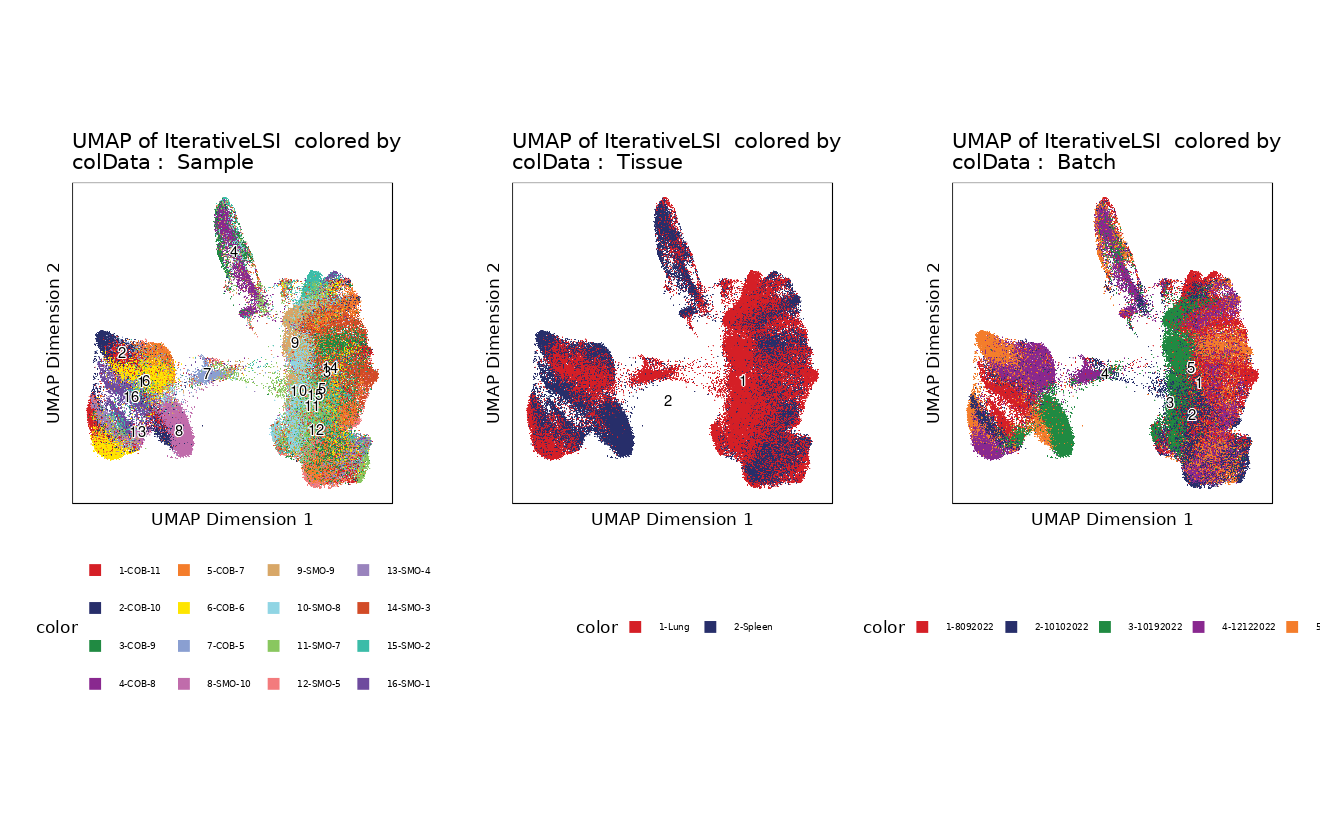

In [17]:
## Visualize data with UMAPs colored by sample, cluster, batch, status
seRNA <- readRDS("~/cluster/projects/u19_multiomics/analyses/u19_seRNA_summarized_experiment.RDS") 
pal <- paletteDiscrete(values = colData(seRNA)$majority_voting)
p1<-plotEmbedding(ArchRProj = proj, colorBy = "cellColData", name = "Sample", embedding = "UMAP")
p2<-plotEmbedding(ArchRProj = proj, colorBy = "cellColData", name = "Clusters", embedding = "UMAP")
p3<-plotEmbedding(ArchRProj = proj, colorBy = "cellColData", name = "Batch", embedding = "UMAP")
p4<-plotEmbedding(ArchRProj = proj, colorBy = "cellColData", name = "Status", embedding = "UMAP")
p5<-plotEmbedding(ArchRProj = proj, colorBy = "cellColData", 
              name = "majority_voting", embedding = "UMAP", pal=pal)

<a id='section3'></a>
## 3 Annotate cell clusters for scATAC-seq data

As not all the cells have matched scRNA and scATAC sequencing data that pass quality checks for our data. We took two approaches to annotate cell type - majority voting and transfer labeling using ArchR::FindTransferAnchors. 

### Majority-voting approach



In [25]:
## UMAPs colored by cell labels from scRNA-seq or clusters from scATAC-seq
pal <- paletteDiscrete(values = colData(seRNA)$majority_voting)

p1 <- plotEmbedding(ArchRProj = proj, colorBy = "cellColData", 
              name = "majority_voting", embedding = "UMAP",
              pal=pal)
plotEmbedding(ArchRProj = proj, colorBy = "cellColData", 
              name = "Clusters", embedding = "UMAP")


ArchR logging to : ArchRLogs/ArchR-plotEmbedding-65385efef782-Date-2024-11-18_Time-14-18-16.log
If there is an issue, please report to github with logFile!

Getting UMAP Embedding

ColorBy = cellColData

Plotting Embedding

1 


ArchR logging successful to : ArchRLogs/ArchR-plotEmbedding-65385efef782-Date-2024-11-18_Time-14-18-16.log

ArchR logging to : ArchRLogs/ArchR-plotEmbedding-653810683e9-Date-2024-11-18_Time-14-18-18.log
If there is an issue, please report to github with logFile!

Getting UMAP Embedding

ColorBy = cellColData

Plotting Embedding

1 
Length of unique values greater than palette, interpolating..



ArchR logging successful to : ArchRLogs/ArchR-plotEmbedding-653810683e9-Date-2024-11-18_Time-14-18-18.log



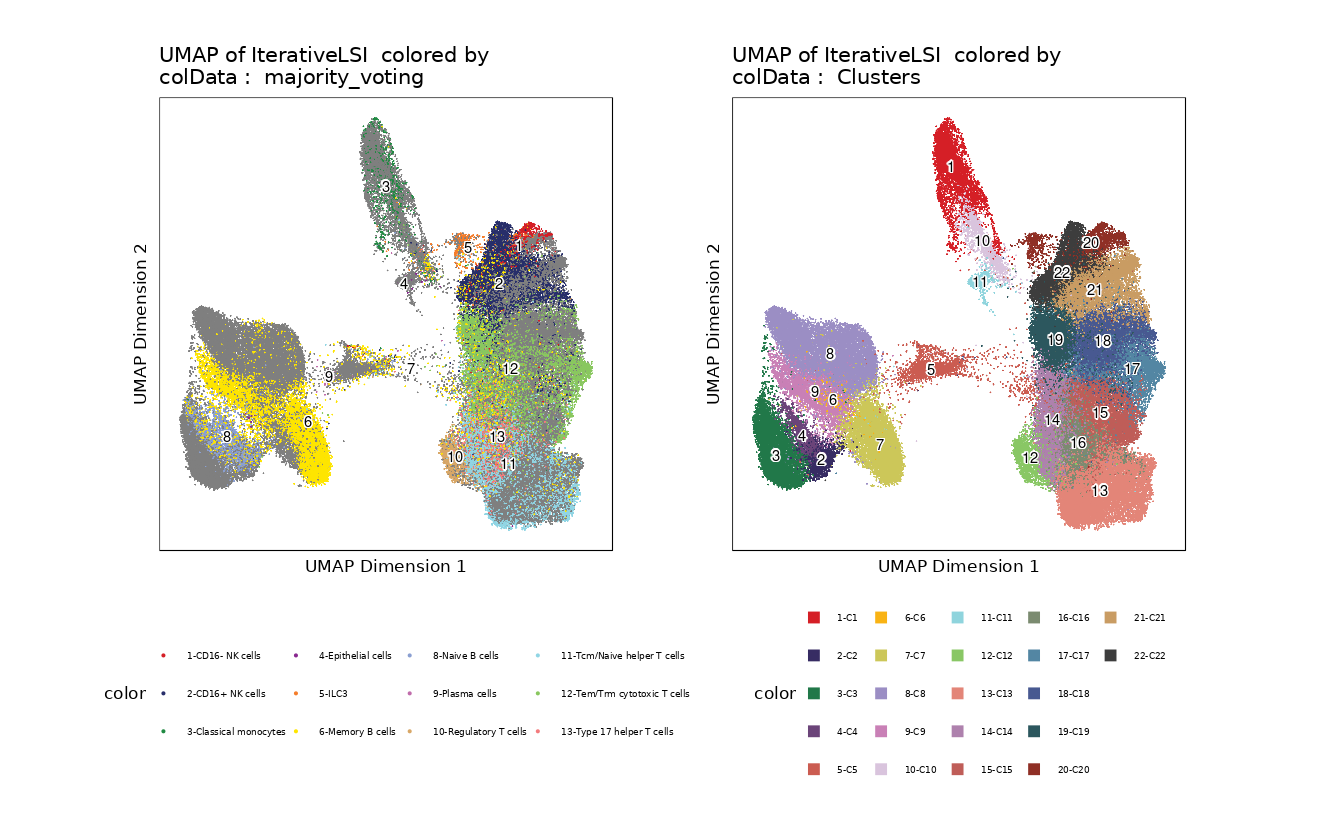

In [26]:
ggAlignPlots(p1, p2, type = "h")

ArchR logging to : ArchRLogs/ArchR-plotEmbedding-777e3663080-Date-2025-04-07_Time-14-35-24.log
If there is an issue, please report to github with logFile!

Getting UMAP Embedding

ColorBy = cellColData

Plotting Embedding

1 


ArchR logging successful to : ArchRLogs/ArchR-plotEmbedding-777e3663080-Date-2025-04-07_Time-14-35-24.log



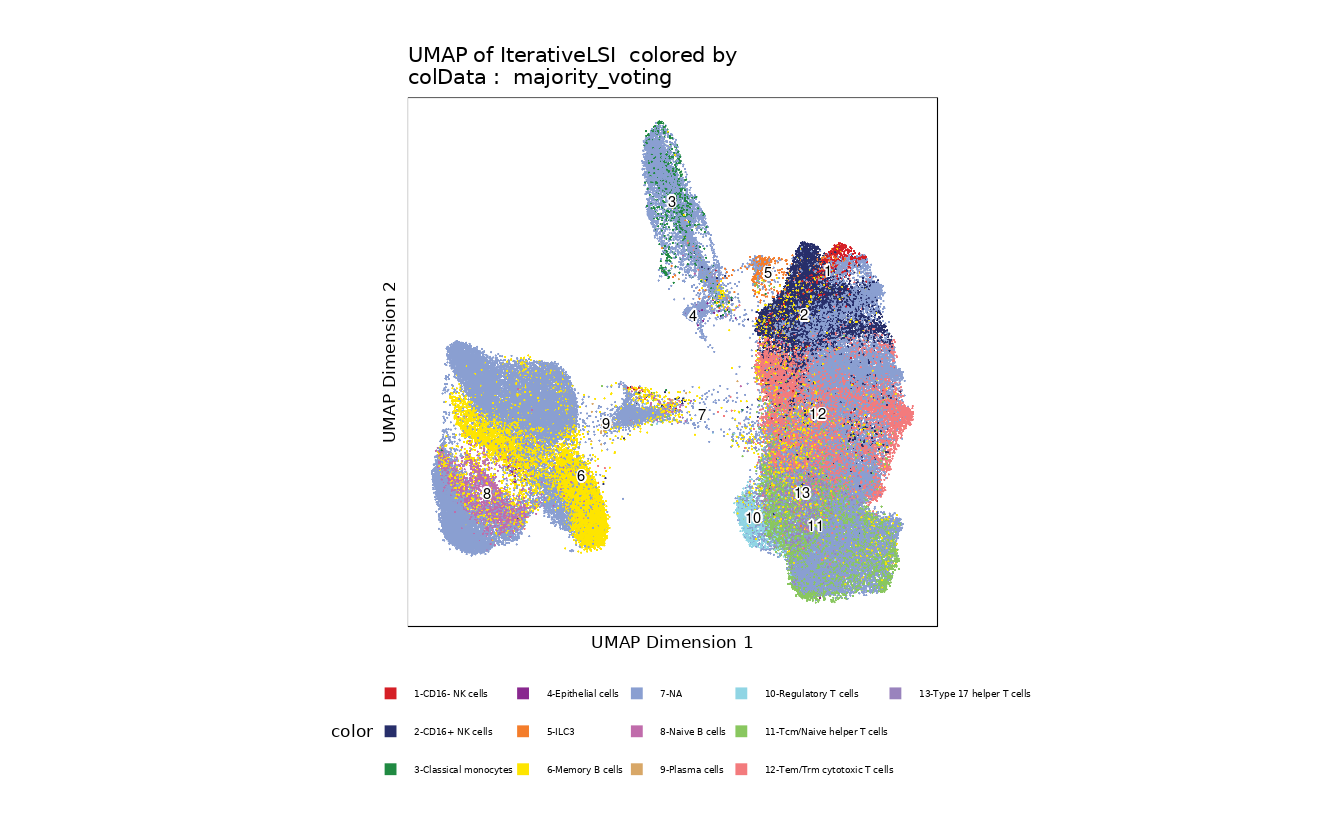

In [26]:
plotEmbedding(ArchRProj = proj, colorBy = "cellColData", 
              name = "majority_voting", embedding = "UMAP")

In [143]:
## Rename cell types to match with scRNA-seq labels
proj@cellColData$CellType <- 
factor(proj@cellColData$majority_voting,
       labels = c("NK", "NK", "Other",
                  "Other", "Other",
                  "Memory_B", "Naive_B", "Other",
                  "Treg", "CD4_T", "CD8_T", "Th17"))

majority_types <- 
lapply(unique(proj@cellColData$Clusters), function(i){
        df = proj@cellColData[proj@cellColData$Clusters == i, ]
        majority_ct = names(sort(table(df$majority_voting), decreasing = TRUE)[1])
        return(majority_ct)}
    )

majority_types<-data.frame(Clusters = unique(proj@cellColData$Clusters),
                           MatchedCellType = unlist(majority_types))

## Two clusters with ambiguity in assigning cell types were given a dual label

majority_types[majority_types$Clusters == "C16", ]$MatchedCellType <-"Th17/CD4_T"
majority_types[majority_types$Clusters == "C14", ]$MatchedCellType<-"CD8/CD4_T"

proj@cellColData$MatchedCellType<-left_join(data.frame(proj@cellColData), 
                                            majority_types, by="Clusters") %>% pull(MatchedCellType)

### Transfer labeling approach

In [7]:
## Match cell names across two assays 
seRNA <- readRDS("data/u19_seRNA_summarized_experiment.RDS")
lungID_list <-c("SMO-2", "SMO-3", "SMO-5", "SMO-7", "SMO-8", "SMO-9")
spleenID_list <- c("SMO-1", "SMO-4", "SMO-10")
cellnames<- unlist(
    lapply(colnames(seRNA), function(i){
    if(grepl("lungs", i)){
        sampleID = lungID_list[as.numeric(strsplit(i, "-")[[1]][2])]
        cellID = strsplit(strsplit(i, "#")[[1]][2], "-")[[1]][1]
        return(sprintf("%s#%s-1", sampleID, cellID))
        }else{
        sampleID = spleenID_list[as.numeric(strsplit(i, "-")[[1]][2])]
        cellID = strsplit(strsplit(i, "#")[[1]][2], "-")[[1]][1]
        return(sprintf("%s#%s-1", sampleID, cellID))
    }}))

colnames(seRNA) <- cellnames
seATAC_meta <- data.frame(proj@cellColData) %>% mutate(cellID = rownames(proj@cellColData))
seRNA_meta <- data.frame(seRNA@colData) %>% mutate(cellID = rownames(seRNA@colData))
joint_meta <- left_join(seATAC_meta %>% select(-CellType), 
                        seRNA_meta %>% select(cellID, CellType))

proj@cellColData$CellType <- joint_meta$CellType

In [ ]:
# Unconstrained integration using seRNA data
projInteg <- addGeneIntegrationMatrix(
    ArchRProj = proj, 
    useMatrix = "GeneScoreMatrix",
    matrixName = "GeneIntegrationMatrix",
    reducedDims = "IterativeLSI",
    seRNA = seRNA,
    addToArrow = FALSE,
    groupRNA = "CellType",
    nameCell = "predictedCell_Un",
    nameGroup = "predictedGroup_Un",
    nameScore = "predictedScore_Un",
    force = TRUE
)

# intersect scATAC-seq clusters with predicted Group
cM <- as.matrix(confusionMatrix(projInteg$Clusters, projInteg$predictedGroup_Un))
preClust <- colnames(cM)[apply(cM, 1 , which.max)]
cbind(preClust, rownames(cM)) #Assignments

In [ ]:
seATAC_meta <- data.frame(projInteg@cellColData) %>% mutate(cellID = rownames(projInteg@cellColData))
seRNA_meta <- data.frame(seRNA@colData) %>% mutate(cellID = rownames(seRNA@colData))
joint_meta <- left_join(seATAC_meta %>% select(-CellType), 
                        seRNA_meta %>% select(cellID, CellType))
projInteg@cellColData$CellType <- joint_meta$CellType

p1 <- plotEmbedding(
    projInteg, 
    colorBy = "cellColData", 
    name = "Clusters"
)

In [ ]:
pal <- paletteDiscrete(values = colData(seRNA)$CellType)
pdf("u19_peaks_tissue/Plots/Plot-UMAP-RNA-Integration-subCluster.pdf")
p1 <- plotEmbedding(
    projInteg, 
    colorBy = "cellColData", 
    name = "Clusters"
)
p2 <- plotEmbedding(
    projInteg, 
    colorBy = "cellColData", 
    name = "CellType", 
    pal = pal
)
p3 <- plotEmbedding(
    projInteg, 
    colorBy = "cellColData", 
    name = "predictedGroup_Un", 
    pal = pal
) 
p1
p2
p3
dev.off()
#pdf(p1, p2, p3, name = "Plot-UMAP-RNA-Integration-subCluster.pdf", ArchRProj = projInteg, addDOC = FALSE, width = 5, height = 5)


In [ ]:
metadata<-left_join(data.frame(proj@cellColData), 
          sample_cov %>% mutate(Sample=core_ID,
                                Tissue = cells,
                                Batch = as.character(submission_date),
                                Status = grepl("asthmatic", `Asthmatic status`),
                                Age = factor(Age),
                                ) %>%
          select(c(Sample, Tissue, Status, Batch, Sex, Age, Race)),
          by = "Sample"
          )
proj@cellColData<-cbind(proj@cellColData, 
                       metadata %>% select(Tissue, Status, Batch, Sex, Age, Race))

In [ ]:
p1<-plotEmbedding(ArchRProj=proj, colorBy="cellColData", 
                    name="Tissue", embedding="UMAP",
                    ) 
p2<-plotEmbedding(ArchRProj=proj, colorBy="cellColData", 
                    name="Status", embedding="UMAP",
                    ) 
p3<-plotEmbedding(ArchRProj=proj, colorBy="cellColData", 
                    name="predictedGroup_Un", embedding="UMAP",
                    ) + theme_minimal(base_size=15)

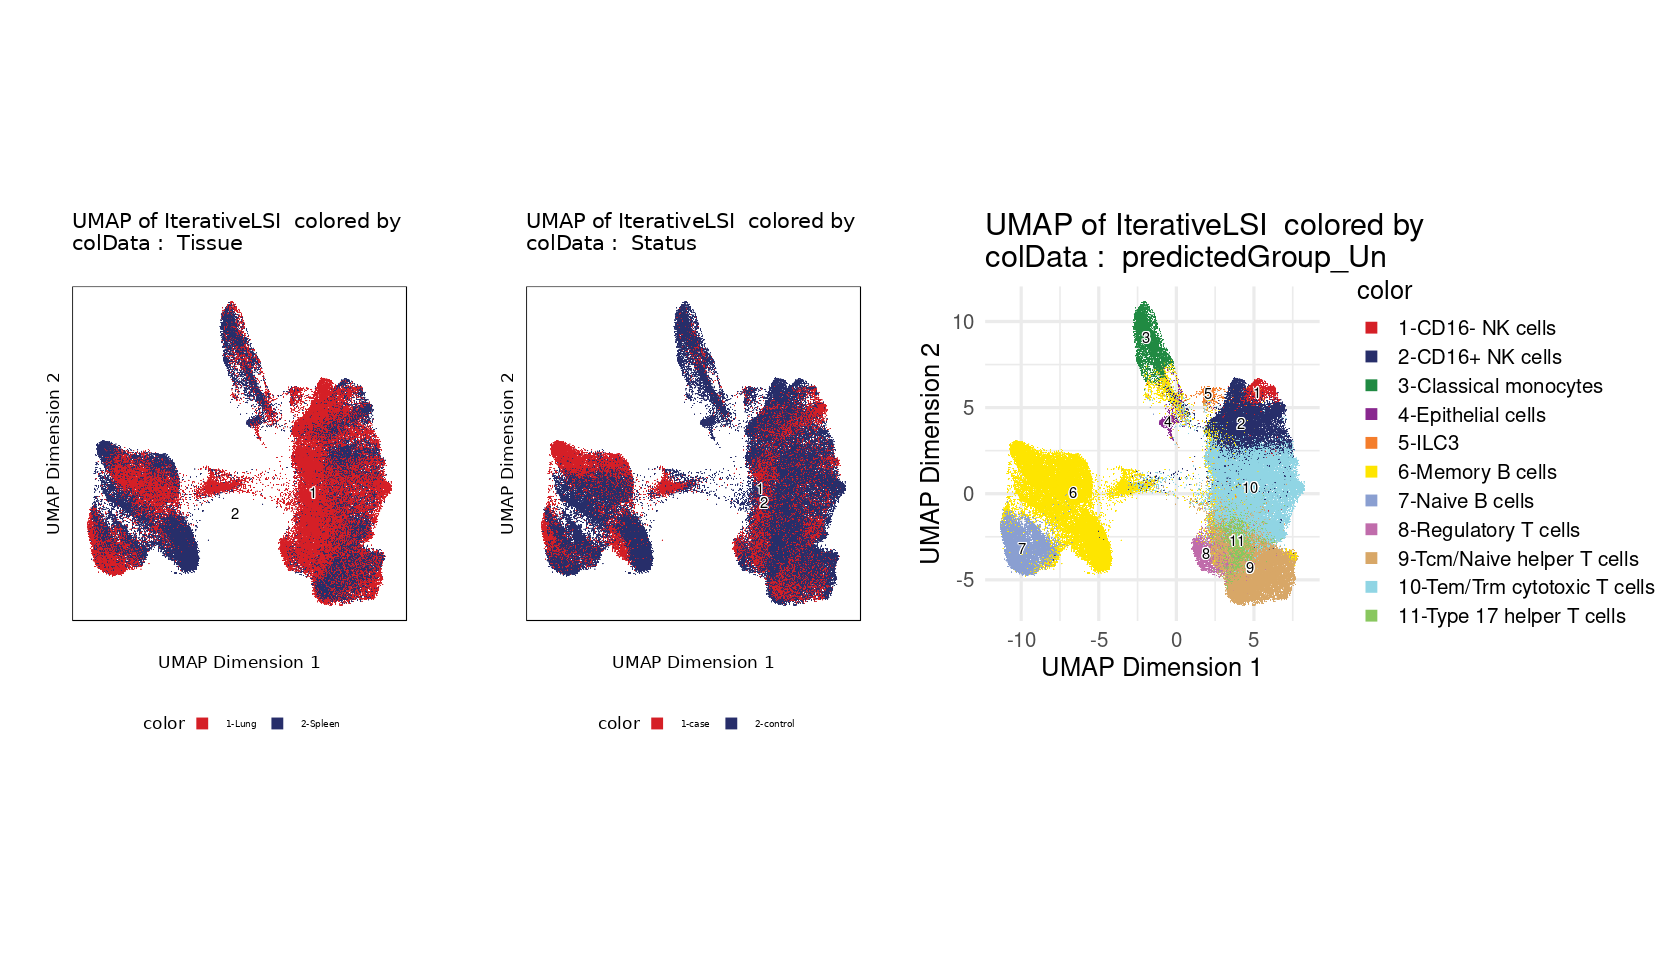

In [4]:
## UMAPs colored by transferred cell labels
ggAlignPlots(p1, p2, p3, type = "h")

### Verifying cell type annotations

In [ ]:
## Rename cell types for simplicity
proj@cellColData$PredCellType <-
    factor(proj@cellColData$predictedGroup_Un,
           labels = c("NK","NK",
                      "Other", "Other", "Other",
                      "Memory_B", "Naive_B", "Treg",
                     "CD4_T", "CD8_T",        
                     "Th17"))

In [ ]:
## Identify marker genes for each cell type based on gene scores
markerGS <-
    getMarkerFeatures(
      ArchRProj = proj, 
      useMatrix = "GeneScoreMatrix",
      groupBy = "PredCellType",
      testMethod = "wilcoxon",
      bias = c("TSSEnrichment", "log10(nFrags)")
    )

markerList <- 
    getMarkers(markerGS, cutOff = "FDR <= 0.01 & Log2FC >= 1.25")

In [48]:
lung_TRM_genes<-strsplit("PHLDA1,RBPJ,DOCK5,GOLIM4,CD101,ATP10D,XCL1,KRT81,FAM167A,RTKN2,ITGA1,ITGAE,CXCR6,PDCD1,DUSP6,CRTAM,IL17A,IL2,IFNG",
                         ",")[[1]]
markerGenes <- c(
    "PAX5", "MS4A1", "EBF1", "MME", #B-cell lineage
    "CD3D", "CD4", "CD8A", "IL7R", "TRAC", "IL32", #TCells
    "CD248", "SLC4A10", "EDAR", "CTLA4", 
    "NCAM1", "KIR2DL4", "ALDH1A1", "LYPD2",
    "CCL5", "IFNG", "ZFP36L2","AOAH", "GZMA", "GZMB", #Th1
    "PPARG", "IL13", "IL5", "HPGDS", "IL17RB","CHDH", #Th2
    "IL17A", "IL17F", "IL23R","ABCB1",
    "IL32", "PELI1", "CD27", "ICA1", "TIGIT", "IL2RA", "FOXP3", "GATA3")

heatmapGS <- markerHeatmap(
  seMarker = markerGS, 
  cutOff = "FDR <= 0.1 & Log2FC >= 0.58", 
  labelMarkers = markerGenes,
  transpose=FALSE,
  clusterCols = FALSE,
)

In [ ]:
## UMAPs colored by predicted gene scores

proj <- addImputeWeights(proj)
p <- plotEmbedding(
    ArchRProj = proj, 
    colorBy = "GeneScoreMatrix", 
    name = markerGenes, 
    embedding = "UMAP",
    quantCut = c(0.01, 0.95),
    imputeWeights = getImputeWeights(proj)
)

<a id='section4'></a>
## 4 Peak calling
* Make pseudobulk replicates by adding group coverages for each cell type 
* Call peaks using MACS2
* Quantify reads in peaks

### Peak calling based on tissues

In [ ]:
## Group cellls by tissue and cell type
proj@cellColData$CellGroup <- paste(proj@cellColData$Tissue, 
                                     proj@cellColData$PredCellType, sep="_")

## Create replicates by bootstrapping within each group
proj <- addGroupCoverages(ArchRProj = proj, groupBy = "", force=TRUE)

## Call peaks 
### load conda environment jupyter to call macs2
proj <- addReproduciblePeakSet(
    ArchRProj = proj, 
    groupBy = "CellGroup", 
)
## Replace peak matrix with the new one
proj<-addPeakMatrix(proj, force=TRUE)

In [ ]:
## Identify marker peaks using the Wilcoxon ranksum test
markerPeaks <- getMarkerFeatures(
    ArchRProj = proj, 
    useMatrix = "PeakMatrix", 
    groupBy = "PredCellType",
    bias = c("TSSEnrichment", "log10(nFrags)"),
    testMethod = "wilcoxon"
)

ArchR logging to : ArchRLogs/ArchR-getMarkerFeatures-5ab4bf727e5-Date-2025-04-15_Time-16-24-58.log
If there is an issue, please report to github with logFile!

MatrixClass = Sparse.Integer.Matrix

2025-04-15 16:25:02 : Matching Known Biases, 0.053 mins elapsed.



### Summarize the number of peaks called in each group

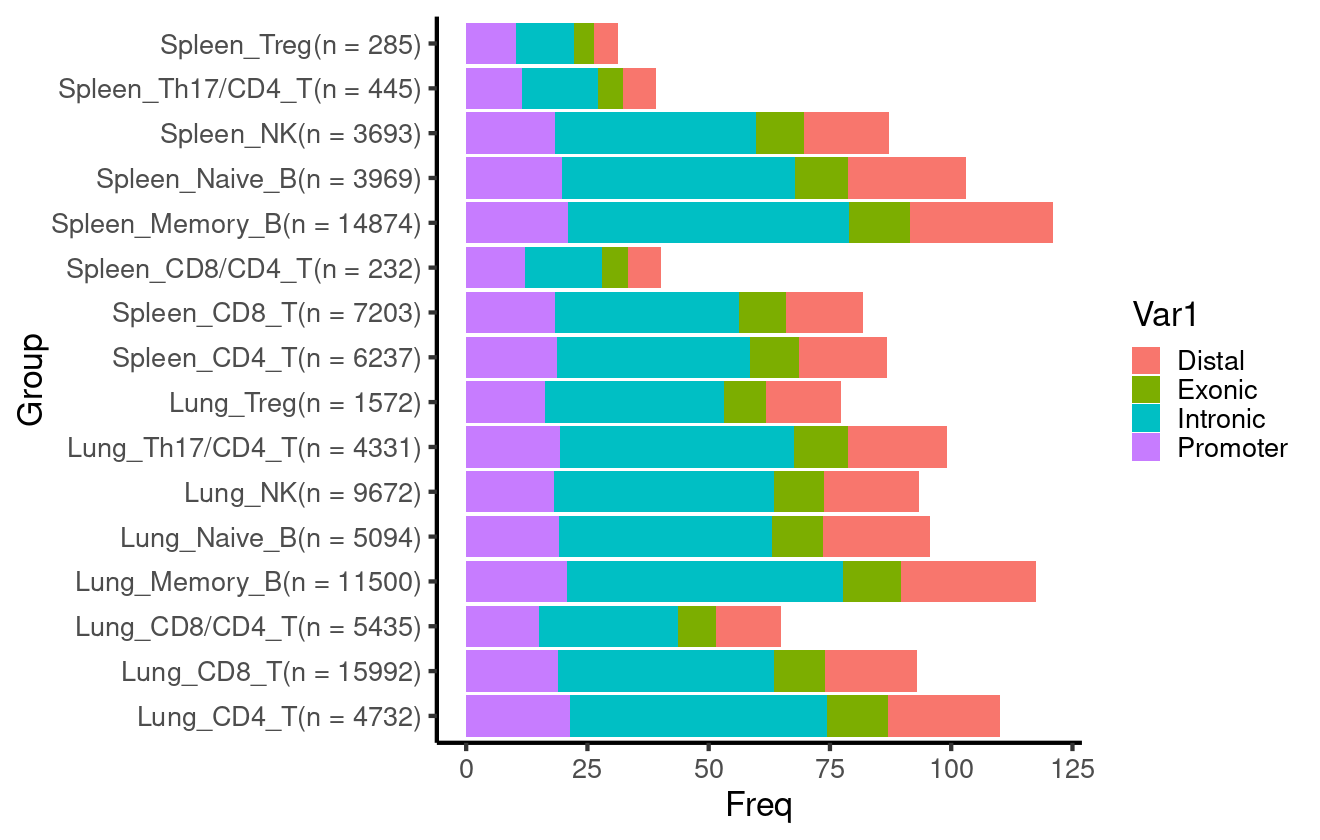

In [6]:
ggplot(data=proj@peakSet@metadata$PeakCallSummary %>%
       filter(grepl("T", Group) | grepl("B", Group)|grepl("NK", Group)), 
       aes(x=Group, y=Freq, fill=Var1)) + 
geom_col() + coord_flip() + theme_classic(base_size = 20)

In [ ]:
# get meatrix from peaks called in lungs to perform topic models
peakMatrix <- getMatrixFromProject(
  ArchRProj = proj,
  useMatrix = "PeakMatrix",  # or "TileMatrix", "PeakMatrix", etc.
  useSeqnames = NULL,             # specify chromosomes if needed
  verbose = TRUE,
  binarize = TRUE,               # set to TRUE if you need a binarized matrix
  threads = 8, #getArchRThreads(),
  logFile = createLogFile("getMatrixFromProject")
)

counts<-t(peakMatrix@assays@data$PeakMatrix) #49235x125597

# check peak sparsity
mean(counts>0)
saveRDS(counts, "../output/u19_full_atac_by_cell_types_peakMatrix.RDS")

In [74]:
proj@cellColData$Status <- ifelse(grepl("asthmatic", proj@cellColData$Status), "case", "control")

In [ ]:
## make pseudobulk replicates
proj@cellColData$CellGroup <- 
paste(proj@cellColData$Tissue,  proj@cellColData$CellType, sep="_")

proj <- addGroupCoverages(ArchRProj = proj, groupBy = "CellGroup", force=TRUE)

## call peaks 
proj <- addReproduciblePeakSet(
    ArchRProj = proj, 
    groupBy = "CellGroup", 
    #pathToMacs2 = "~/scratch-midway2/env/jupyter/bin/macs2"
)
## save a copy for the current projject
#saveArchRProject(ArchRProj = proj, outputDirectory = "u19_peaks_celltype", load=FALSE)

## add peak matrix to a new projject 
proj <- addPeakMatrix(proj, force = TRUE)
getAvailableMatrices(proj)
saveArchRProject(proj)

## save again

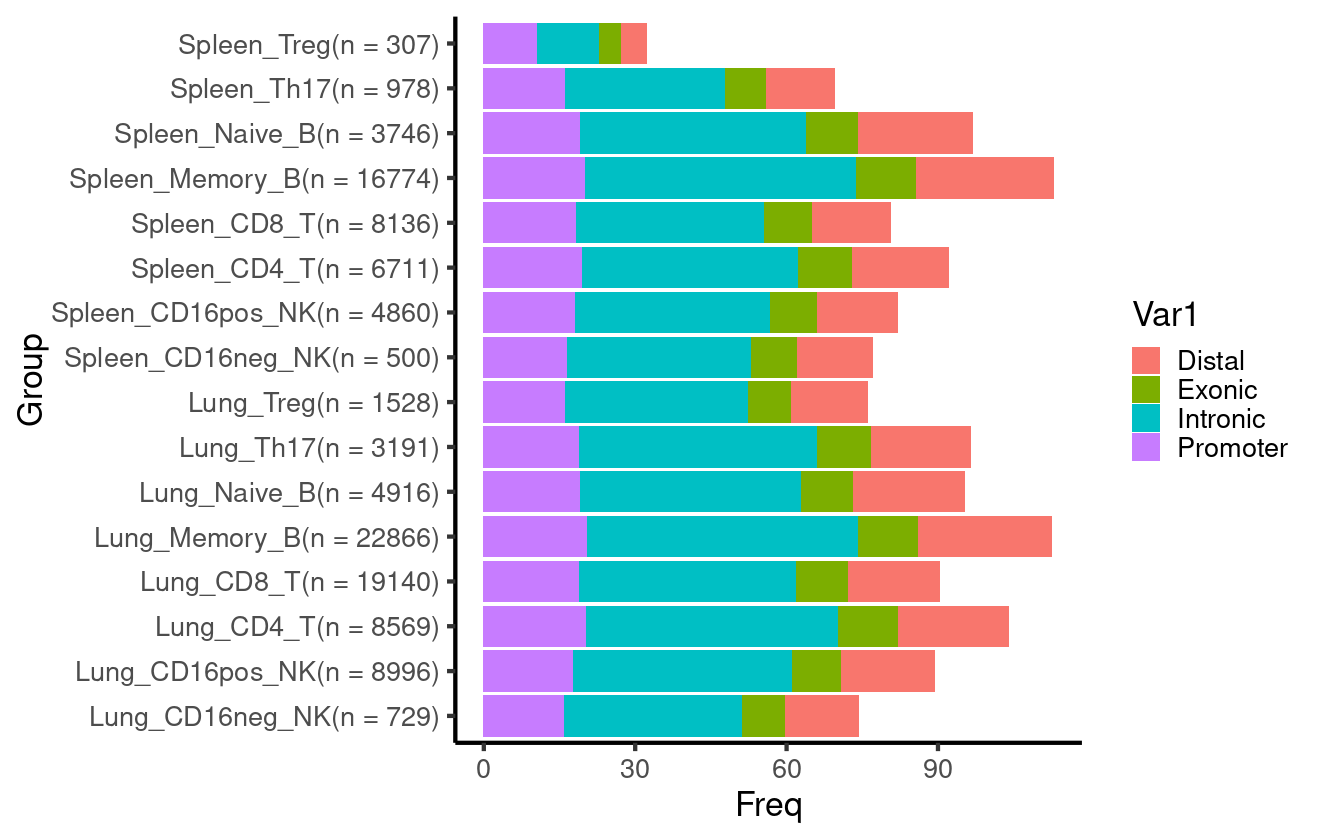

In [21]:
ggplot(data=proj@peakSet@metadata$PeakCallSummary %>%
       filter(grepl("T", Group) | grepl("B", Group)|grepl("NK", Group)), 
       aes(x=Group, y=Freq, fill=Var1)) + 
geom_col() + coord_flip() + theme_classic(base_size = 20)

In [12]:
gginput <-
data.frame(proj@cellColData) %>%
       group_by(Tissue, PredCellType) %>%
       summarise(n = n())

gginput <- 
left_join(gginput, 
    data.frame(proj@cellColData) %>%
       group_by(Tissue) %>%
       summarise(tissue_sum = n()))

gginput

`summarise()` has grouped output by 'Tissue'. You can override using the
`.groups` argument.
Joining with `by = join_by(Tissue)`


Tissue,PredCellType,n,tissue_sum
<chr>,<chr>,<int>,<int>
Lung,CD4_T,4732,60190
Lung,CD8/CD4_T,5435,60190
Lung,CD8_T,15992,60190
Lung,Memory_B,11500,60190
Lung,NK,9672,60190
Lung,Naive_B,5094,60190
Lung,Other,1862,60190
Lung,Th17/CD4_T,4331,60190
Lung,Treg,1572,60190


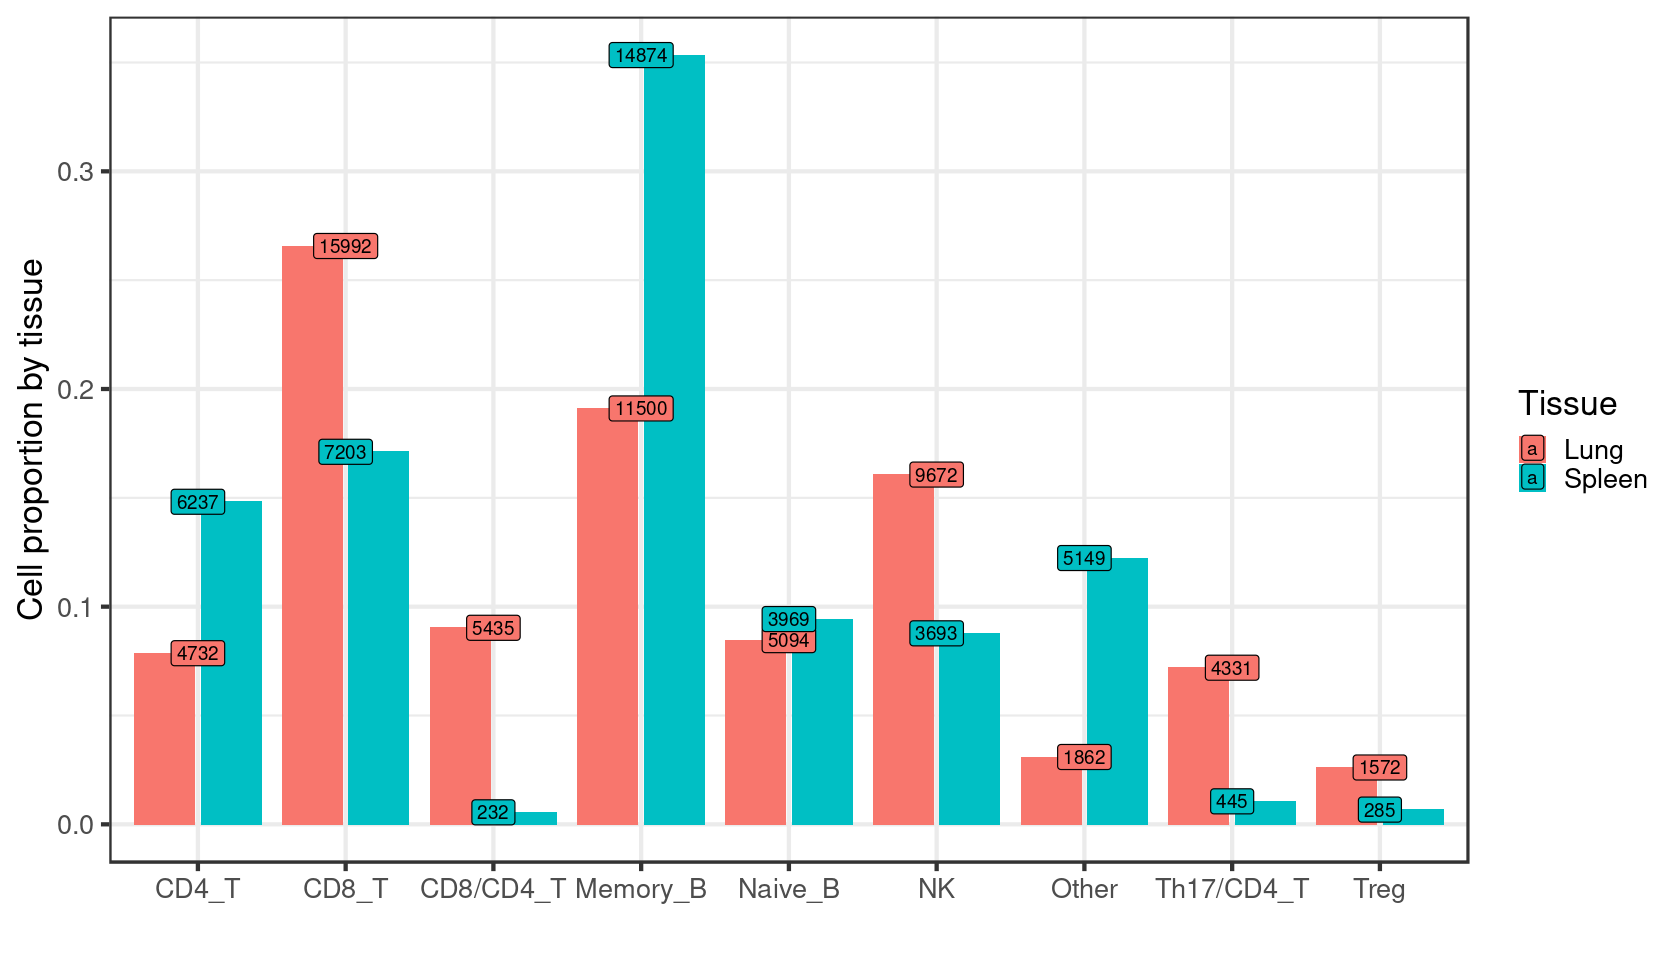

In [17]:
options(repr.plot.width=14, repr.plot.height=8)

ggplot(gginput,
       aes(x = PredCellType,
           y = n/tissue_sum,
           fill = Tissue,
           label = n)) + 
geom_col(position = "dodge2") + 
geom_label() + ylab("Cell-type proportion") + xlab("") + 
theme_bw(base_size = 20)



In [15]:
head(ntotal_by_celltype)

Tissue,PredCellType,n
<chr>,<chr>,<int>
Lung,CD4_T,4732
Lung,CD8/CD4_T,5435
Lung,CD8_T,15992
Lung,Memory_B,11500
Lung,NK,9672
Lung,Naive_B,5094


In [46]:
ntotal <-
data.frame(proj@cellColData) %>%
       group_by(Status, Tissue, PredCellType) %>%
       summarise(nTotal = n())

df <- 
    data.frame(proj@cellColData) %>%
    group_by(Status, Tissue, PredCellType) %>%
    summarise(n = n())

`summarise()` has grouped output by 'Status', 'Tissue'. You can override using the
`.groups` argument.
`summarise()` has grouped output by 'Status', 'Tissue'. You can override using the
`.groups` argument.


In [47]:
df <-left_join(df, ntotal)
df

Joining with `by = join_by(Status, Tissue, PredCellType)`


Status,Tissue,PredCellType,n,nTotal
<chr>,<chr>,<chr>,<int>,<int>
case,Lung,CD4_T,1094,1094
case,Lung,CD8/CD4_T,3326,3326
case,Lung,CD8_T,3376,3376
case,Lung,Memory_B,4654,4654
case,Lung,NK,1499,1499
case,Lung,Naive_B,1312,1312
case,Lung,Other,403,403
case,Lung,Th17/CD4_T,146,146
case,Lung,Treg,533,533


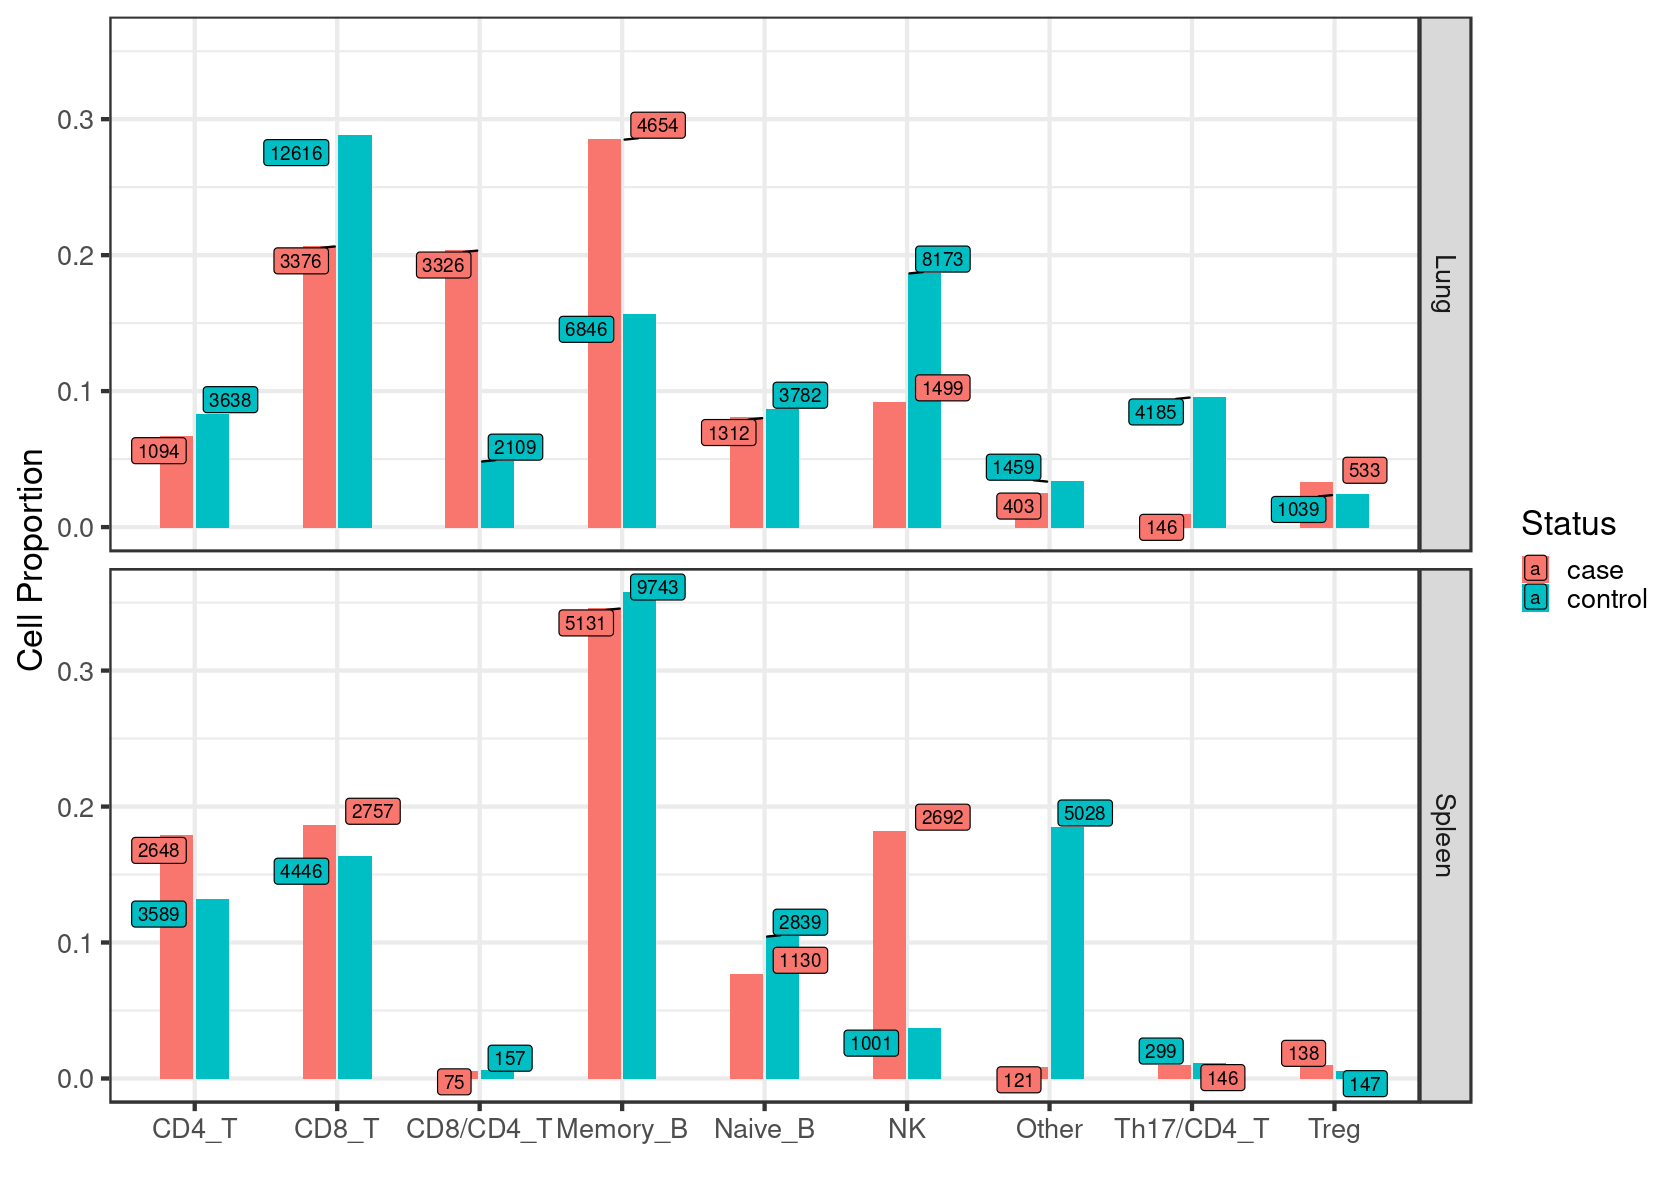

In [43]:
options(repr.plot.width=14, repr.plot.height=10)
library(ggrepel)
ggplot(df,
       aes(x = PredCellType,
           y = n/nTotal,
           fill = Status,
           label = n)) + 
#geom_col(width = 0.5) + 
geom_col(position = "dodge2", width = 0.5) + 
geom_label_repel() + ylab("Cell Proportion") + xlab("") + 
theme_bw(base_size = 20) + facet_grid(Tissue ~.)

<a id='section5'></a>
## 5 Identifying marker peaks for each cell type

For identifying marker peaks for each cell type, we called ArchR::addMarkerFeatures() on the peak matrix comparing one cell type against all others using wilcoxon rank sum test, adjusted by TSS enrichment and logarithm of fragment counts.


In [ ]:
markerPeaks <- getMarkerFeatures(
    ArchRProj = proj, 
    useMatrix = "PeakMatrix", 
    groupBy = "PredCellType",
  bias = c("TSSEnrichment", "log10(nFrags)"),
  testMethod = "wilcoxon"
)

<a id='section6'></a>
## 6 Cross-tissue differential accessibility analysis by pseudobulk

For identifying differentially accessible peaks between tissue, we first generated count matrix by donor, tissue and cell type and then tested peaks with differential accessibility using DESeq2. We also adjusted for covariates including batch, ethnicity, age, and sex.

In [ ]:
# Aggregate peak matrix by sample and cell type

peakMatrix <- ArchR::getMatrixFromProject(proj, useMatrix = "PeakMatrix") # returns matrix and metadata

peakMatrix$CellGroup <-
  paste(peakMatrix$Sample,
        peakMatrix$PredCellType,
        sep = "_")

countBySample <- 
  sapply(unique(peakMatrix$CellGroup), function(i) {
  rowSums(assays(peakMatrix[, peakMatrix$CellGroup == i])$PeakMatrix)
})

In [ ]:
library(DESeq2)
## Extract metadata from archR object
## Load previously generated atac count matrix

DA_list <-
    lapply(unique(metadata$PredCellType), function(i) {
        idx = which(metadata$PredCellType == i)
        dds <- DESeqDataSetFromMatrix(countData = countBySample[, idx], 
                                  colData = metadata[idx, ],
                                  design = ~ factor(Batch) + Race + Sex + Status + Tissue)
        dds <- DESeq(dds, betaPrior = FALSE)
        mm <- model.matrix(design(dds), colData(dds))
        qr(mm)$rank
        ncol(mm)
        print(qr(mm)$rank == ncol(mm))
        res <- results(dds, contrast = c("Tissue", "Lung", "Spleen"))
        return(res)
        })


In [ ]:
## Sumamrize the number of differentially accessible peaks in each cell type
names(DEG_list) <- unique(metadata$PredCellType)

tests <- lapply(names(DEG_list), function(i) {
  data.frame(DEG_list[[i]], cluster = gsub("-", "_", i)) %>%
    filter(!is.na(log2FoldChange))
})

DA_tbl <- do.call(rbind, tests)

gginput <-
    DA_tbl %>% 
      mutate(avg_log2FC = log2FoldChange) %>%
      filter(cluster != "Other" & padj <= 0.05) %>%
      mutate(group = case_when(avg_log2FC >= 1~ "Lung Up-regulated", 
                                 avg_log2FC <= -1 ~ "Spleen Up-regulated")) 


df <-
  data.frame(table(gginput$cluster, gginput$group)) %>%
    pivot_wider(names_from = "Var2", 
                values_from = "Freq") 
df[match(ct_order, df$Var1), ]

### Example of genomic tracks for *GNLY*

In [ ]:
## Example of genomic tracks for GNLY 

library(colorspace)
proj@cellColData$TissueID <- ifelse(proj@cellColData$Tissue == "Lung", "L", "S")
proj@cellColData$CellGroup <- paste0(proj@cellColData$PredCellType, 
                                     "(", proj@cellColData$TissueID,
                                     ")")

lung_col = pal_atac[1:5]
names(lung_col) <- c("Naive_B", "Memory_B", "NK", "CD4_T", "CD8_T")
names(lung_col)  <- paste0(names(lung_col), "(L)")
spleen_col = lighten(pal_atac[1:5], amount = 0.3)
names(spleen_col) <-  c("Naive_B", "Memory_B", "NK", "CD4_T", "CD8_T")
names(spleen_col) <- paste0(names(spleen_col), "(S)")

p <- plotBrowserTrack(
    ArchRProj = proj, 
    groupBy = "CellGroup", 
    geneSymbol = c("GNLY"),
    features =  getPeakSet(proj),
    upstream = 20000,
    downstream = 20000,
    useGroups = unlist(lapply(c("Naive_B", "Memory_B", "NK", "CD8_T", "CD4_T"), function(i){
      paste0(i, c("(L)", "(S)"))
    })), 
    facetbaseSize = 13,
    baseSize = 13,
    pal = c(lung_col, spleen_col)
)
#pdf("output/marker_peaks_cross_tissue_DA_HSPA1A.pdf")
p
grid::grid.newpage()
grid::grid.draw(p$GNLY)